# Project Code

**Author:** Wikoria Mleczko

**Question:** Does the share of trips by bike type (electric, classic) differ between Divvy stations inside Equity Priority Areas and those outside them? Is there still a difference when adjusting for the number of stations?

# Datsets used: 

*Divvy trip data*: Divvy System Data. We will retrieve ride start/end times and start/end stations from this dataset. We will select a reasonable time period based on data availability and scope of our project.

*Divvy equity priority data*: Divvy Equity Priority Area. We will use this dataset to determine the boundaries of Divvy’s designated Equity Priority Areas and to determine which Divvy stations fall inside and outside them, by matching the coordinates to the boundary shapes. 



## Variables

My question compares stations inside and outside EPAs, but bike type is recorded per trip, so I look at it two ways.

**Station level.** For each station, I count the trips and the share that were electric. Each station is one observation, so I can compare the distribution of shares inside and outside EPAs.

**Trip level.** I treat each trip as one observation, label it EPA or non-EPA based on its starting station, and record its bike type. I then compare the overall electric share in each group. Busier stations contribute more trips here, so this shows how the typical rider behaves. It's unadjusted, so I'll later check whether the difference holds after accounting for the number of stations.

## Data Cleaning

In [3]:
# Importing necessary packages
import pandas as pd 
import geopandas as gpd
import matplotlib.pyplot as plt
import seaborn as sns
from shapely import wkt

In [4]:
# Reading the divvy dataset
divvy_trips_df = pd.read_csv("data/202609-divvy-tripdata.csv")

# Showing the shape of the dataset
print(divvy_trips_df.shape)
divvy_trips_df.head()

(770562, 13)


,ride_id,rideable_type,started_at,ended_at,start_station_name,start_station_id,end_station_name,end_station_id,start_lat,start_lng,end_lat,end_lng,member_casual
0,B3C076B2D6BAC911,electric_bike,2026-09-01 19:28:37.087,2026-09-01 19:33:03.047,NaN,NaN,NaN,NaN,41.87,-87.67,41.87,-87.66,member
1,468834E54297FB3F,electric_bike,2026-09-24 20:38:01.486,2026-09-24 20:44:54.382,NaN,NaN,NaN,NaN,41.91,-87.70,41.90,-87.71,member
2,276E6265CF1F0238,electric_bike,2026-09-24 20:01:27.138,2026-09-24 20:08:32.366,NaN,NaN,NaN,NaN,41.90,-87.71,41.91,-87.70,member
3,F297F75928C557B7,electric_bike,2026-09-29 21:20:03.900,2026-09-29 21:42:29.179,NaN,NaN,NaN,NaN,41.96,-87.68,41.92,-87.72,member
4,0C21D327353C6D73,electric_bike,2026-09-30 13:23:43.088,2026-09-30 13:27:10.920,NaN,NaN,NaN,NaN,41.79,-87.60,41.79,-87.59,member


In [5]:
#Listing the columns 
print(divvy_trips_df.columns.tolist())

['ride_id', 'rideable_type', 'started_at', 'ended_at', 'start_station_name', 'start_station_id', 'end_station_name', 'end_station_id', 'start_lat', 'start_lng', 'end_lat', 'end_lng', 'member_casual']


In [6]:
# Identifying the missing values 
divvy_trips_df.isna().sum()

ride_id                    0
rideable_type              0
started_at                 0
ended_at                   0
start_station_name    160341
start_station_id      160341
end_station_name      170033
end_station_id        170033
start_lat                  0
start_lng                  0
end_lat                  644
end_lng                  644
member_casual              0
dtype: int64

In [7]:
# Identifying duplicate rows 
print(divvy_trips_df.duplicated().sum())

0


In [8]:
# Reading the equity priority area (EPA) dataset 
epa_df = gpd.read_file("data/Divvy_Equity_Priority_Area_20261121.csv")

# Showing the shape of the dataset
print(epa_df.shape)
epa_df.head()

(1, 4)


,shape_name,polygon,created_time,modified_time
0,Divvy Equity Priority Area,"POLYGON ((-87.586843 41.644696, -87.586865 41....",02/24/2023,02/24/2023


In [9]:
#Listing the columns 
print(epa_df.columns.tolist())

['shape_name', 'polygon', 'created_time', 'modified_time']


In [11]:
#Checking missing values in EPA dataset
print(epa.isna().sum())
print(epa.geometry.isna().sum())

shape_name       0
polygon          0
created_time     0
modified_time    0
geometry         0
dtype: int64
0


In [34]:
# Since the cordinates are stored as text, we need to convert them into a polygon object 
# Storing the polygon text into a variable named polygon
polygon = epa_df.columns[1] 

# Converting each text into a polygon object (with shape so spacial operations can used) in a new column named geometry
epa_df["geometry"] = epa_df[polygon].apply(wkt.loads)

# making the table iknto a dataframe with geometry and a coordinate reference system (CRS) 
epa = gpd.GeoDataFrame(epa_df, geometry="geometry", crs="EPSG:4326")

# Checking shape 
print(epa.shape)
print(epa.geom_type)
print(epa.is_valid)

(1, 5)
0    Polygon
dtype: str
0    True
dtype: bool


In [12]:
# Checking the bike types in the file 
print(divvy_trips_df["rideable_type"].value_counts())

# Making a copy of the divvy dataset to work with
clean_divvy = divvy_trips_df.copy()

# Shape before data cleaning
print("Before Cleaning:", clean_divvy.shape[0])

# Since all trips are either electric_bike or classic_bike don't need to drop any values
# Converting the timestamps to datetimes, no N/A values so don't have to drop any values
clean_divvy["started_at"] = pd.to_datetime(clean_divvy["started_at"], errors="coerce")
clean_divvy["ended_at"] = pd.to_datetime(clean_divvy["ended_at"], errors="coerce")

# To account for any "unrealistic" data such as trips that are under 1 min or over a day, we will drop any trips that are under 1 min or over 24 hours
clean_divvy["duration_min"] = (clean_divvy["ended_at"] - clean_divvy["started_at"]).dt.total_seconds() / 60
clean_divvy = clean_divvy[(clean_divvy["duration_min"] >= 1) & (clean_divvy["duration_min"] <= 24 * 60)]

# Shape after data cleaning
print("After Cleaning:", clean_divvy.shape[0])

rideable_type
electric_bike    580638
classic_bike     189924
Name: count, dtype: int64
Before Cleaning: 770562
After Cleaning: 751319


# Exploratory Data Analysis (EDA)

In [13]:
# Marking each trip as EPA or non-EPA via a spatial join

# Turning each point into a point on the map using the start coordinates of each trip 
trip_points = gpd.GeoDataFrame(
    clean_divvy.copy(),
    geometry=gpd.points_from_xy(clean_divvy["start_lng"], clean_divvy["start_lat"]),
    crs="EPSG:4326",
)

# Checking each trip point against an EPA boundary to see if it is inside
trip_epa = gpd.sjoin(trip_points, epa[["geometry"]], how="left", predicate="within")

# Turning the match column into a boolean column indicating if each trip is inside an EPA boundary
clean_divvy["in_epa"] = trip_epa["index_right"].notna().values

print(clean_divvy["in_epa"].value_counts())

in_epa
False    735090
True      16229
Name: count, dtype: int64


In [14]:
# Value counts of divvy trips that are inside/outside EPA areas and bike type 
print(clean_divvy.groupby(["in_epa", "rideable_type"]).size())

in_epa  rideable_type
False   classic_bike     185386
        electric_bike    549704
True    classic_bike       3905
        electric_bike     12324
dtype: int64


In [ ]:
# Checking how many trips don't have a start station ID, for EPA and non-EPA areas
# False = outside EPAs, True = inside EPAs
print(clean_divvy.groupby("in_epa")["start_station_id"].apply(lambda s: s.isna().mean() * 100))

in_epa
False    20.011155
True     24.782796
Name: start_station_id, dtype: float64


In [16]:
# Checking the percentage of trips that were electric bikes for EPA and non-EPA areas
# False = outside EPAs, True = inside EPAs
trip_share = clean_divvy.groupby("in_epa")["rideable_type"].apply(
    lambda s: (s == "electric_bike").mean() * 100).round(2)

print(trip_share)

in_epa
False    74.78
True     75.94
Name: rideable_type, dtype: float64


In [17]:
# Determining the number of trips per station (drop any that do not have an ID because they cannot be identified)
station_trips = clean_divvy.dropna(subset = ["start_station_id"])

# Creating a table for the number of trips per station, broken down by EPA and non-EPA areas, and the number of electric bike trips
stations_summary = station_trips.groupby(["start_station_id", "in_epa"]).agg(
    total_trips=("rideable_type", "size"),
    electric_trips=("rideable_type", lambda s: (s == "electric_bike").sum()),
).reset_index()

In [18]:
# Finding the share of electric bike trips for each station
stations_summary["electric_share"] = (
    stations_summary["electric_trips"] / stations_summary["total_trips"] * 100
)

print(stations_summary["electric_share"])

0       65.135453
1       53.991597
2       74.716981
3       60.020243
4       59.598854
          ...    
1548    70.648464
1549    66.847826
1550    48.689139
1551    65.497076
1552    71.428571
Name: electric_share, Length: 1553, dtype: float64


In [ ]:
# summary table of stations by EPA and non-EPA areas
print(stations_summary.groupby("in_epa").agg(
    n_stations=("start_station_id", "size"),
    median_trips=("total_trips", "median"),
    median_share=("electric_share", "median"),
).round(2))

        n_stations  median_trips  median_share
in_epa                                        
False         1021         294.0         69.88
True           532          10.0         72.73


# Data Visualizations

In [30]:
area_names = {False: "Outside EPA", True: "Inside EPA"}

# Flag trips that have a start station ID
clean_divvy["has_station"] = clean_divvy["start_station_id"].notna()

# One row per station with its location and EPA label, for the map
station_coords = (
    clean_divvy.dropna(subset=["start_station_id"])
    .groupby("start_station_id")[["start_lat", "start_lng", "in_epa"]]
    .first()
    .reset_index()
)
stations_df = gpd.GeoDataFrame(
    station_coords,
    geometry=gpd.points_from_xy(station_coords["start_lng"], station_coords["start_lat"]),
    crs="EPSG:4326",
)

# Chicago background outline
chicago = gpd.read_file("data/chicago_commpop.geojson")

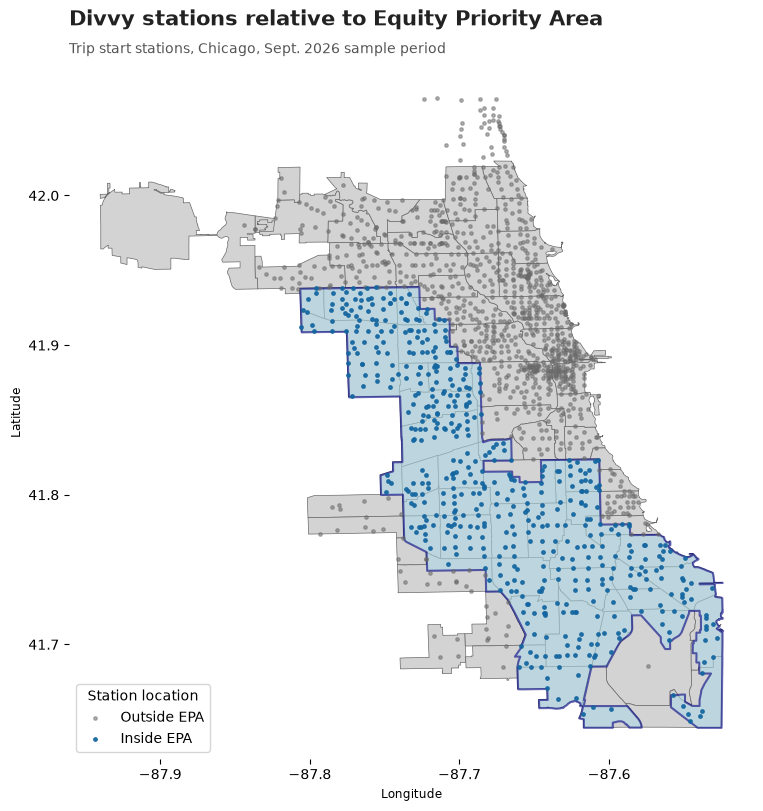

In [ ]:
# Graph 1: Making a map of the Divvy stations relative to the EPA area

chicago = gpd.read_file("data/chicago_commpop.geojson")

fig, ax = plt.subplots(figsize=(8, 8), layout="constrained")

# Creating the background: city outline
chicago.plot(ax=ax, color="lightgrey", edgecolor="dimgray", linewidth=0.5)
# Shading the EPA area
epa.plot(ax=ax, color="lightblue", edgecolor="navy", linewidth=1.5, alpha=0.6)

# Shading stations: grey for outside the EPA, blue for inside the EPA
stations_df[~stations_df["in_epa"]].plot(
    ax=ax, color="dimgray", markersize=6, alpha=0.5, label="Outside EPA"
)
stations_df[stations_df["in_epa"]].plot(
    ax=ax, color="#1466a0", markersize=6, alpha=0.9, label="Inside EPA"
)

# Setting the title, axis labels, aspect ratio, legend, and grid
ax.set_title("Divvy stations relative to Equity Priority Area",
             fontsize=15, fontweight="bold", color="#222222", loc="left", pad=30)
ax.text(0, 1.02, "Trip start stations, Chicago, Sept. 2026 sample period",
        transform=ax.transAxes, fontsize=10, color="#555555", ha="left")
ax.set_aspect("equal")
ax.set(xlabel="Longitude", ylabel="Latitude")
ax.legend(loc="lower left", frameon=True, title="Station location")
ax.grid(False)
for spine in ax.spines.values():
    spine.set_visible(False)

plt.show()

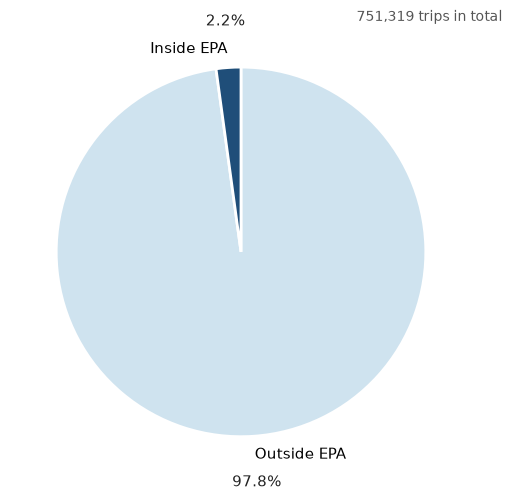

In [ ]:
# Graph #2: Showing the share of trips starting inside vs. outside the EPA

# counting the # of trips + index
counts = clean_divvy["in_epa"].value_counts().sort_index()
# getting the labels for each category
labels = [area_names[k] for k in counts.index]
# getting total number of trips
total = counts.sum()

fig, ax = plt.subplots(figsize=(6, 6), facecolor="white")

# Making the pie chart
wedges, texts, autotexts = ax.pie(
    counts.values,
    labels=labels,
    colors=["#cfe3ef", "#1f4e79"],
    startangle=90,
    counterclock=False,
    autopct=lambda p: f"{p:.1f}%",
    pctdistance=1.25,                      
    wedgeprops={"edgecolor": "white", "linewidth": 2},
    textprops={"fontsize": 11},
)

# Text for labels
for t in autotexts:
    t.set_color("#222222")

ax.text(0.75, 1.0, f"{total:,} trips in total", transform=ax.transAxes,
        fontsize=10, color="#555555", ha="left")

plt.show()

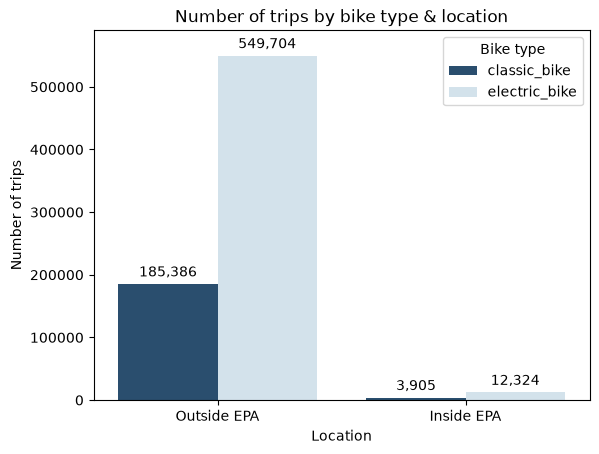

In [ ]:
# Graph 3: Number of trips by station location and bike type

# Grouping the data by EPA area and bike type, counting the number of trips, and resetting the index
counts = clean_divvy.groupby(["in_epa", "rideable_type"]).size().reset_index(name="trips")
# Adding a column for the area names based on the boolean in_epa column
counts["area"] = counts["in_epa"].map(area_names)

# Creating the barplot
ax = sns.barplot(data=counts, x="area", y="trips", hue="rideable_type",
                 palette=["#1f4e79", "#cfe3ef"])

# Printing the exact number above each bar
for container in ax.containers:
    ax.bar_label(container, fmt="{:,.0f}", padding=3)

# Setting the title, axis labels, legend, and y-limit
ax.set_title("Number of trips by bike type & location")
ax.set_xlabel("Location")
ax.set_ylabel("Number of trips")
ax.legend(title="Bike type")
ax.set_ylim(0, 590000)
plt.show()

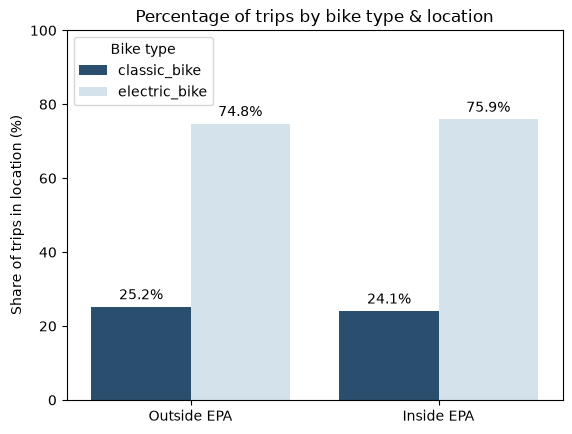

In [ ]:
# Graph 4: Share of trips by station location and bike type

# Calculating the share of each location group's trips that were each bike type
counts["pct"] = counts["trips"] / counts.groupby("in_epa")["trips"].transform("sum") * 100

# Making the barplot
ax = sns.barplot(data=counts, x="area", y="pct", hue="rideable_type",
                 palette=["#1f4e79", "#cfe3ef"])
# Printing the exact number above each bar
for container in ax.containers:
    ax.bar_label(container, fmt="%.1f%%", padding=3)

# Setting the title, axis labels, legend, and y-limit
ax.set_title("Percentage of trips by bike type & location")
ax.set_xlabel("")
ax.set_ylabel("Share of trips in location (%)")
ax.set_ylim(0, 100)
ax.legend(title="Bike type")
plt.show()

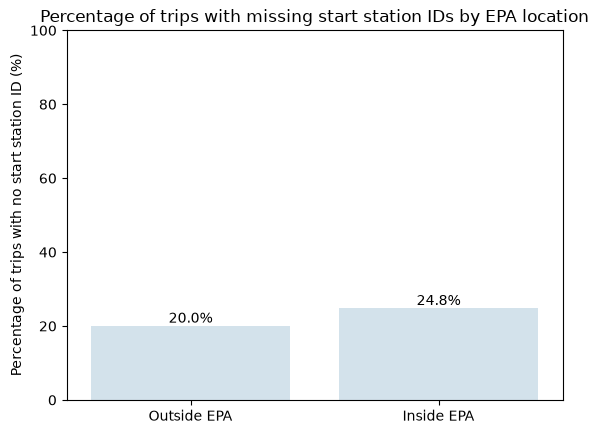

In [ ]:
# Graph 5: Share of trips with missing start station IDs by location

# Defining the variable missing_pct that splits the trip record by EPA area and slects only records that have a station_id
missing_pct = (
    clean_divvy.groupby("in_epa")["start_station_id"]
    # Boolean for missing values, as a percentage
    .apply(lambda s: s.isna().mean() * 100)
    .reset_index(name="missing_pct")
)
# Mapping the boolean in_epa column to area names
missing_pct["area"] = missing_pct["in_epa"].map(area_names)

# Making the bar plot
ax = sns.barplot(data=missing_pct, x="area", y="missing_pct", color="#cfe3ef")
#  Printing the exact number above each bar
for container in ax.containers:
    ax.bar_label(container, fmt="%.1f%%")
# Setting the title, axis labels, legend, and y-limit
plt.title("Percentage of trips with missing start station IDs by EPA location")
plt.xlabel("")
plt.ylabel("Percentage of trips with no start station ID (%)")
plt.ylim(0, 100)
plt.show()

C:\Users\kmmle\AppData\Local\Temp\ipykernel_12140\3811765485.py:8: UserWarning: The palette list has more values (2) than needed (1), which may not be intended.
  ax = sns.barplot(data=no_id_counts, x="area", y="trips", hue="rideable_type",


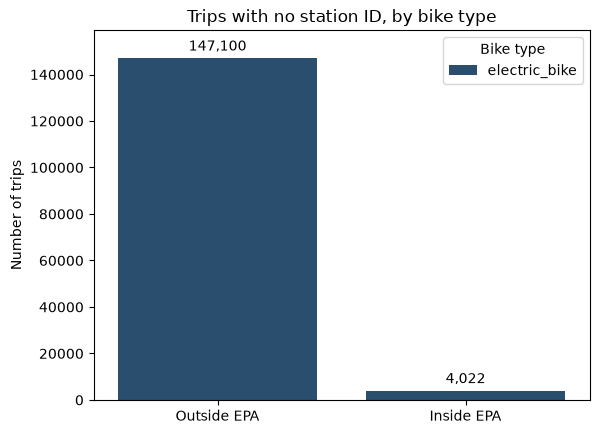

In [ ]:
# Graph 6: Number of trips with missing start station IDs by location and bike type

# Filtering the dataset to only include rows where has_station = False
no_id = clean_divvy[~clean_divvy["has_station"]]
# Couting the # of stationless trips by EPA location and bike type into a new column named trips
no_id_counts = no_id.groupby(["in_epa", "rideable_type"]).size().reset_index(name="trips")
no_id_counts["area"] = no_id_counts["in_epa"].map(area_names)

# Making the barplot
ax = sns.barplot(data=no_id_counts, x="area", y="trips", hue="rideable_type",
                 palette=["#1f4e79", "#cfe3ef"])
#  Printing the exact number above each bar
for container in ax.containers:
    ax.bar_label(container, fmt="{:,.0f}", padding=3)
# Setting the title, axis labels, legend, and y-limit
ax.set_title("Trips with no station ID, by bike type")
ax.set_xlabel("")
ax.set_ylabel("Number of trips")
ax.legend(title="Bike type")
ax.set_ylim(0, 159000)
plt.show()

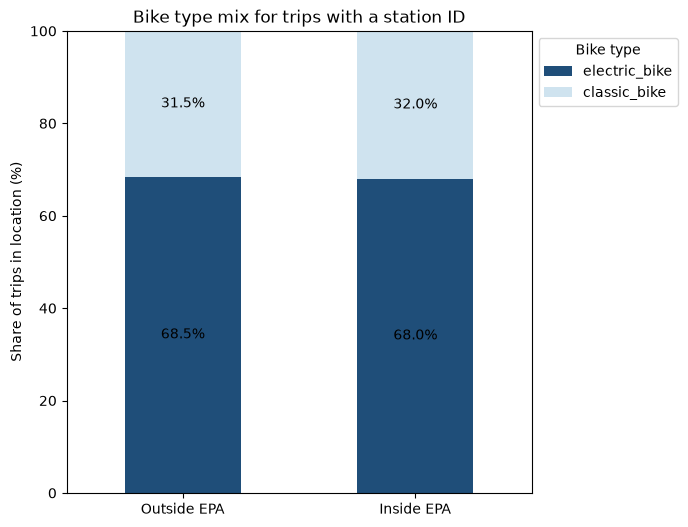

In [ ]:
# Graph 7: Percentage of each bike type within each EPA group, using trips with a station ID

# Filtering the dataset so theres only stations that have a station_id
with_id = clean_divvy[clean_divvy["has_station"]]

# Making a new variables called mix_pct
mix_pct = (
    # Counts trips by EPA area and bike type
    with_id.groupby(["in_epa", "rideable_type"]).size()
    # Calculating each bike type's percentage share within each EPA group and reshaping columns
    .groupby(level=0).transform(lambda s: s / s.sum() * 100).unstack("rideable_type")
)
# Assinging specific bar color based on bike type
mix_pct = mix_pct[["electric_bike", "classic_bike"]]
mix_pct.index = mix_pct.index.map(area_names)

# Plotting the stacked bar-plot
ax = mix_pct.plot(kind="bar", stacked=True, color=["#1f4e79", "#cfe3ef"],
                  figsize=(6, 6))
# Adding percentage in the bar
for container in ax.containers:
    ax.bar_label(container, fmt="%.1f%%", label_type="center")

# Setting the title, labels, y-limit, and legend
ax.set_title("Bike type mix for trips with a station ID")
ax.set_xlabel("")
ax.set_ylabel("Share of trips in location (%)")
ax.set_ylim(0, 100)
ax.legend(title="Bike type", loc="upper left", bbox_to_anchor=(1, 1))
plt.show()